In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.stats import norm, genpareto, gaussian_kde, kstest

np.random.seed(42)

## 0. Théorie

**1. Idée centrale**

Les méthodes classiques (VaR gaussienne, volatilité historique) décrivent bien le cœur de la distribution des rendements, mais sous-estiment systématiquement les pertes extrêmes. La TVE étudie directement la queue de distribution, c'est-à-dire les événements rares, sans supposer une forme particulière pour toute la loi.

Exemple : le krach du 19 octobre 1987 (Dow Jones −22,6 % en une séance) était, selon un modèle gaussien, un événement de probabilité quasi nulle. Il est cohérent avec une queue lourde, que la TVE permet de modéliser.

**2. Les deux approches fondamentales**

**a) Maxima par blocs (Block Maxima)**

On découpe l'historique en blocs (par exemple, un bloc = une année) et l'on retient le maximum de pertes de chaque bloc. Le théorème de Fisher-Tippett-Gnedenko affirme que, sous des conditions générales, ces maxima suivent asymptotiquement une loi GEV (Generalized Extreme Value) :

$$G(x) = \exp\left[ - \left(1 + \xi \frac{x - \mu}{\sigma} \right)^{-1/\xi}\right], \qquad 1 + \xi \frac{x - \mu}{\sigma} > 0$$

- $\xi > 0$ : queue lourde (loi de Fréchet). C'est le cas le plus pertinent pour les marchés financiers.
- $\xi = 0$ : queue exponentielle (loi de Gumbel).
- $\xi < 0$ : queue bornée (loi de Weibull).

Inconvénient : on perd de l'information, car un bloc ne retient qu'un seul événement, même si plusieurs événements extrêmes ont eu lieu.

**b) Dépassements de seuil (Peaks Over Threshold, POT)**

On fixe un seuil élevé $u$ et l'on modélise les excès $y = X − u$ conditionnellement à $X > u$. Le théorème de Pickands-Balkema-de Haan indique que cette distribution converge vers une loi de Pareto généralisée (GPD) :

$$G_{\xi, \beta}(y) = 1 - \left(1 + \frac{\xi y}{\sigma}\right)^{-1/\xi}$$

- Location ($\mu$): Le seuil ou valeur minimale à partir de laquelle la distribution est mesurée.
- Scale ($\sigma$): La dispersion de la distribution (Plus $\sigma$ est grand, plus les valeurs extrêmes sont dispersées.)
- Shape ($\xi$): Le comportement de la queue de la distribution $\Rightarrow$ déterminer si la distribution a une variance finie ou infinie, ainsi que l'épaisseur de la queue :
    - $\xi > 0$: queue lourde (de type Pareto).
    - $\xi = 0$: queue exponentielle.
    - $\xi < 0$: queue bornée (avec une limite supérieure finie).
  
C'est l'approche la plus utilisée en finance, car elle exploite mieux les données.

## 1. Téléchargement des données

In [ ]:
# Paramètres
TICKER = "^FCHI"
START_DATE = "2016-09-30"
END_DATE = "2026-10-01"
CONFIDENCE_LEVELS = [0.95, 0.99]
THRESHOLD_QUANTILE = 0.95
TRADING_DAYS = 252
ANNUALIZATION = np.sqrt(TRADING_DAYS)

# Données brutes
data = yf.download(TICKER, start=START_DATE, end=END_DATE, interval="1d", auto_adjust=True, progress=False)
data.columns = data.columns.get_level_values(0)

## 2. Description statistique

Ticker : ^FCHI
Période : 2016-10-03 - 2026-09-30
Observations : 2558
Rendement journalier en moyen : 0.028776%
Volatilité journalière en moyenne : 1.092690%
Le pire rendement journalier : -12.276774%


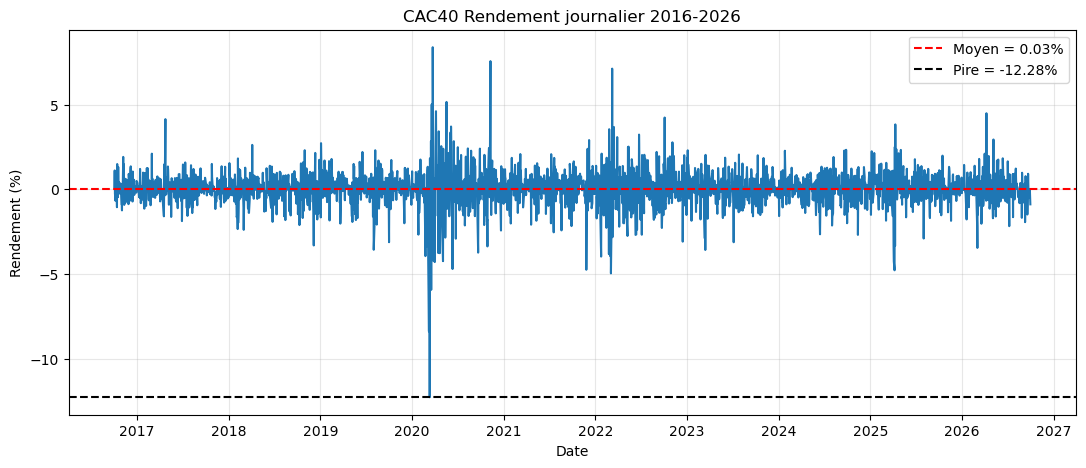

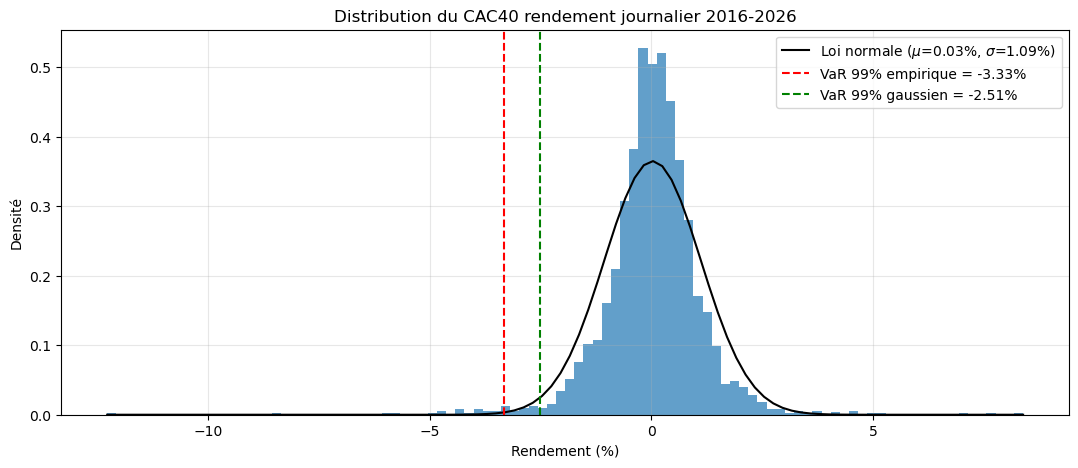

In [ ]:
# Rendements
close = data["Close"]
df = pd.DataFrame({"Close": close})
df["Log-rendement"] = np.log(df["Close"] / df["Close"].shift(1))
df["Rendement simple"] = df["Close"].pct_change()
df = df.dropna()

# Pertes
df["Loss"] = -df["Rendement simple"]  # Loss < 0 == Rendement > 0
returns = df["Rendement simple"].values
losses = df["Loss"].values

# Distribution normale
r = returns * 100
mu = np.mean(r)
sigma = np.std(r)
x = np.linspace(r.min(), r.max(), 100)
pdf_normal = norm.pdf(x, mu, sigma)

# VaR 99.9%
var_empirical = np.quantile(r, 0.01)
var_gaussian = mu + sigma * norm.ppf(0.01)

# Display
print("Ticker :", TICKER)
print(f"Période : {df.index.min().date()} - {df.index.max().date()}")
print("Observations :", len(df))
print(f"Rendement journalier en moyen : {np.mean(returns)*100:.6f}%")
print(f"Volatilité journalière en moyenne : {np.std(returns)*100:.6f}%")
print(f"Le pire rendement journalier : {np.min(returns)*100:.6f}%")

plt.figure(figsize=(13, 5))
plt.plot(df.index, returns * 100)
plt.axhline(np.mean(returns) * 100, color="red", linestyle="--", label=f"Moyen = {np.mean(returns) * 100:.2f}%")
plt.axhline(np.min(returns) * 100, color="black", linestyle="--", label=f"Pire = {np.min(returns) * 100:.2f}%")
plt.title("CAC40 Rendement journalier 2016-2026")
plt.xlabel("Date")
plt.ylabel("Rendement (%)")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

plt.figure(figsize=(13, 5))
plt.hist(returns * 100, bins=100, density=True, alpha=0.7)
plt.plot(x, pdf_normal, color="black", label=f"Loi normale ($\mu$={mu:.2f}%, $\sigma$={sigma:.2f}%)")
plt.axvline(var_empirical, color="red", linestyle="--", label=f"VaR 99% empirique = {var_empirical:.2f}%")
plt.axvline(var_gaussian, color="green", linestyle="--", label=f"VaR 99% gaussien = {var_gaussian:.2f}%")
plt.title("Distribution du CAC40 rendement journalier 2016-2026")
plt.xlabel("Rendement (%)")
plt.ylabel("Densité")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

- Regroupement de la volatilité (volatility clustering) : les fortes variations se concentrent en 2020 (Covid), en 2022 (guerre en Ukraine, inflation) et en 2025. Entre ces épisodes, la volatilité est faible et stable.
- Le krach de mars 2020 domine : le rendement de −12,28 % et plusieurs rebonds de plus de +5 % se situent à cette période. C'est le point le plus extrême de l'échantillon.
- Le rendement moyen est proche de zéro par rapport à la dispersion : la moyenne (0,03 %) est négligeable face à l'écart-type (1,09 %).
  
$\rightarrow$ **Le risque est donc surtout une question de dispersion et de queues, non de tendance.**

- Distribution très pointue : la densité au centre atteint environ 0,5, alors qu'une loi normale de même écart-type plafonnerait à environ 0,37. Les rendements se concentrent davantage autour de zéro qu'une loi gaussienne ne le prévoit : c'est la *leptokurtose*.
- Queues épaisses : quelques observations isolées sont très éloignées du cœur (−12 %, −8 %, +7 %, +8 %), alors qu'une loi normale les rendrait pratiquement impossibles.
- Conséquence pour le risque : une VaR gaussienne à 99 % (soit près de -2.51 % par jour) sous-estime les pertes extrêmes observées.

$\rightarrow$ **C'est la motivation directe de la TVE.**

## 3. VaR et ES historiques

In [ ]:
def historical_var_es(loss_series, confidence):
    var = np.quantile(loss_series, confidence)
    tail = loss_series[loss_series >= var]
    es = tail.mean() if len(tail) else var
    return var, es

historical_results = []
for confidence in CONFIDENCE_LEVELS:
    var, es = historical_var_es(losses, confidence)
    historical_results.append({
        "Confidence" : confidence,
        "VaR historique" : var * 100,
        "ES historique" : es * 100,
    })

historical_df = pd.DataFrame(historical_results)
historical_df.round(4)

,Confidence,VaR historique,ES historique
0,0.95,1.5895,2.6103
1,0.99,3.3323,4.6307


Le CAC 40 présente une queue épaisse au niveau de 99 %, avec des pertes moyennes extrêmes environ 60 % plus élevées que celles d'un modèle gaussien. La loi normale sous-estime donc le risque de krach, ce qui justifie la modélisation par TVE.

## 4. GDP estimation avec méthode POT

Quantile du seuil : 0.95
Seuil de perte : 1.59%
Nombre de dépassements : 128
Fraction de dépassements : 5.00%


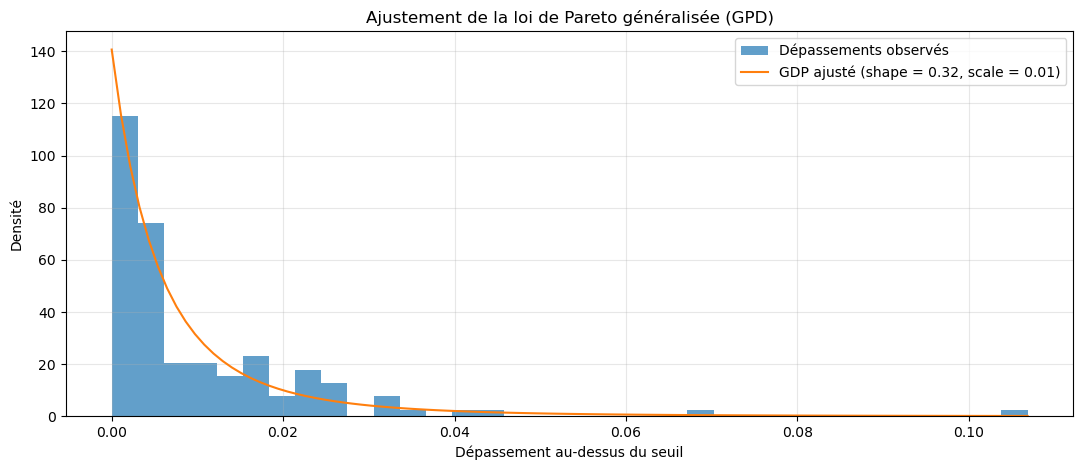

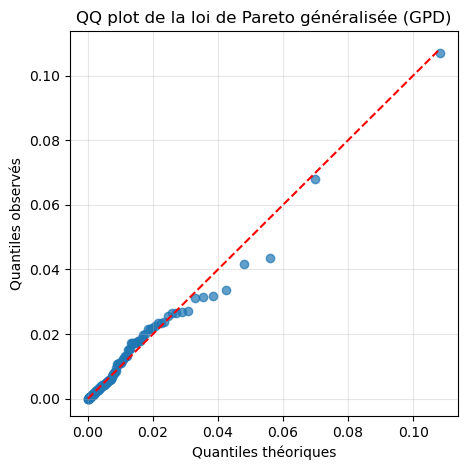

In [ ]:
# Seuil de POT
threshold = np.quantile(losses, THRESHOLD_QUANTILE)
exceedances = losses[losses > threshold]
excesses = exceedances - threshold

n = len(losses)
n_exceed = len(excesses)
p_exceed = n_exceed / n
print("Quantile du seuil :", THRESHOLD_QUANTILE)
print(f"Seuil de perte : {threshold:.2%}")
print("Nombre de dépassements :", n_exceed)
print(f"Fraction de dépassements : {p_exceed:.2%}")

# Modèle GDP
shape, loc, scale = genpareto.fit(excesses, floc=0)   # floc = 0 : location est à 0 car excesses sont fixés au-dessus du seuil

x_grid = np.linspace(0, max(excesses), 100)
plt.figure(figsize=(13, 5))
plt.hist(excesses, bins=35, density=True, alpha=0.7, label="Dépassements observés")
plt.plot(x_grid, genpareto.pdf(x_grid, shape,  loc=0, scale=scale), label=f"GDP ajusté (shape = {shape:.2f}, scale = {scale:.2f})")
plt.title("Ajustement de la loi de Pareto généralisée (GPD)")
plt.xlabel("Dépassement au-dessus du seuil")
plt.ylabel("Densité")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# QQ plot
observed_sorted = np.sort(excesses)
probabilities = (np.arange(1, len(observed_sorted) + 1) - 0.5) / len(excesses)    # Formule de Hazen
theoretical_quantiles = genpareto.ppf(probabilities, shape, loc=0, scale=scale)

limit = max(np.max(theoretical_quantiles), np.max(observed_sorted))
plt.figure(figsize=(5, 5))
plt.scatter(theoretical_quantiles, observed_sorted, alpha=0.7)
plt.plot([0, limit], [0, limit], "r--")
plt.title("QQ plot de la loi de Pareto généralisée (GPD)")
plt.xlabel("Quantiles théoriques")
plt.ylabel("Quantiles observés")
plt.grid(alpha=0.3)
plt.show()

**Histogramme des dépassements**

- La distribution est très décroissante : la grande majorité des excès se situe entre 0 et 1 %, avec un pic net près de zéro.
- La courbe GPD ajustée suit bien cette décroissance rapide, y compris la concentration des petits excès.
- Quelques dépassements isolés apparaissent entre 4 % et 11 %. La GPD les prolonge avec une probabilité faible, sans les reproduire exactement, ce qui est normal avec si peu de points extrêmes.

**QQ-plot**

- Pour les quantiles théoriques inférieurs à 0,03, les points suivent la diagonale. Le modèle décrit bien le cœur de la queue.
- Au-delà de 0,03, les points restent proches de la diagonale, avec une légère sous-estimation vers 0,04 à 0,06 : les observations y sont légèrement en dessous de la prédiction. Les deux plus grands excès (environ 7 % et 11 %) tombent presque sur la droite.
- Il n'y a donc pas de déviation systématique marquée. La GPD est une description raisonnable de la queue, sans signe d'une queue beaucoup plus lourde que le modèle.
  
$\rightarrow$ **Au-delà du seuil de 1,59 %, les pertes décroissent vite, mais la queue reste suffisamment épaisse pour que la loi de Pareto généralisée s'ajuste correctement. Le modèle POT est donc adapté pour estimer la VaR et l'ES.**

## 5. VaR et ES par modèle POT

**Formules POT pour la VaR et l'Expected Shortfall**

- Notations : u = seuil, $N_u$  = nombre de dépassements, $n$ = nombre d'observations, $\zeta_u = N_u / n$, $\hat{\xi}$ et $\hat{\sigma}$ = paramètres GPD estimés sur les excès, $p$ = niveau de confiance.

- Value-at-Risk au niveau p :

$$\mathbb{P}(X > u) = 1 - p \Leftrightarrow x_p = \text{VaR}_p = u + \frac{\sigma}{\xi}\left[\left(\frac{\zeta_u}{1-p}\right)^{\xi} - 1\right], \qquad  1 - p < \zeta_u$$

- Expected Shortfall au niveau p :

$$\text{ES}_p = \frac{\text{VaR}_p + (\hat{\sigma} - \hat{\xi} u)}{1 - \xi} = \text{VaR}_p + \frac{\hat{\sigma} + \hat{\xi}(\text{VaR}_p - u)}{1-\xi}, \qquad \hat{\xi} < 1$$

- Cas limite $\hat{\xi} = 0$ :


$$\text{VaR}_p = u + \hat{\sigma} \ln \left( \frac{\zeta_u}{1-p} \right) \quad , \quad \text{ES}_u = \text{VaR}_p + \hat{\sigma}$$

In [ ]:
def evt_var(losses, threshold, shape, scale, p_exceed, confidence):
    tail_probability = 1 - confidence
    if tail_probability >= p_exceed:
        raise ValueError("Le niveau de confiance est trop faible pour le seuil sélectionné.")
    ratio = p_exceed / tail_probability
    if shape < 1e-6 :
        return threshold + scale * np.log(ratio)
    return threshold + (scale / shape) * (ratio**shape - 1)

def evt_expected_shortfall(var, threshold, shape, scale):
    if shape > 1 or var < threshold:     # Condition de ES et var < threshold (excès soit positif)
        return np.nan
    if shape < 1e-6 :
        return var + scale
    excess_var = var - threshold
    return var + (scale + shape * excess_var) / (1 - shape)

evt_results = []
for confidence in CONFIDENCE_LEVELS:
    var_evt = evt_var(losses, threshold, shape, scale, p_exceed, confidence)
    es_evt = evt_expected_shortfall(var_evt, threshold, shape, scale)
    var_hist, es_hist = historical_var_es(losses, confidence)
    evt_results.append({
        "Confidence" : confidence,
        "VaR historique (%)" : var_hist * 100,
        "VaR EVT (%)" : var_evt * 100,
        "ES historique (%)" : es_hist * 100,
        "ES EVT (%)" : es_evt * 100,
    })

evt_df = pd.DataFrame(evt_results)
evt_df

,Confidence,VaR historique (%),VaR EVT (%),ES historique (%),ES EVT (%)
0,0.95,1.589502,1.590058,2.610306,2.633913
1,0.99,3.332322,3.085553,4.630671,4.828962


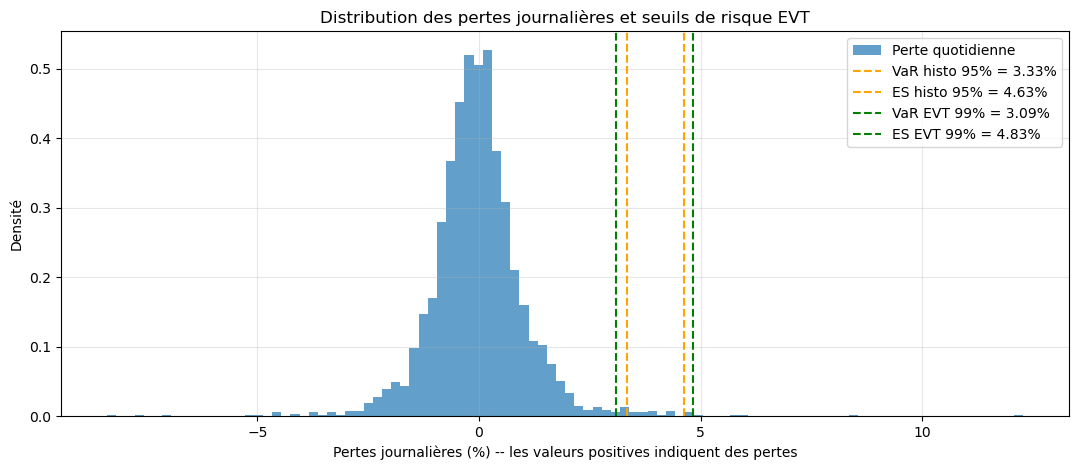

In [ ]:
plt.figure(figsize=(13, 5))
plt.hist(losses*100, bins=100, alpha= 0.7, density=True, label="Perte quotidienne")
plt.axvline(evt_df.iloc[1,1], color="orange", linestyle="--", label=f"VaR histo 95% = {evt_df.iloc[1,1]:.2f}%")
plt.axvline(evt_df.iloc[1,3], color="orange", linestyle="--", label=f"ES histo 95% = {evt_df.iloc[1,3]:.2f}%")
plt.axvline(evt_df.iloc[1,2], color="green", linestyle="--", label=f"VaR EVT 99% = {evt_df.iloc[1,2]:.2f}%")
plt.axvline(evt_df.iloc[1,4], color="green", linestyle="--", label=f"ES EVT 99% = {evt_df.iloc[1,4]:.2f}%")
plt.title("Distribution des pertes journalières et seuils de risque EVT")
plt.xlabel("Pertes journalières (%) -- les valeurs positives indiquent des pertes")
plt.ylabel("Densité")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

- À 95 % : les méthodes concordent (VaR quasi identique, ES à 0,02 point près). C'est attendu, car le seuil u est le quantile 95 % : la VaR EVT est donc quasiment égale à u par construction. Le test ne départage pas les deux approches à ce niveau.

- À 99 % : les deux méthodes divergent.

    - VaR EVT inférieure (3,09 % contre 3,33 %). L'estimation historique repose sur environ 26 observations, donc elle est bruitée. La GPD lisse la queue et donne une valeur plus stable.
    - ES EVT supérieure (4,83 % contre 4,63 %). L'ES moyenne toute la queue au-delà de la VaR. Une GPD ajustée sur 128 excès, dont quelques-uns très grands (mars 2020), attribue davantage de masse aux pertes profondes que la moyenne empirique des 26 pires jours.

## 6. Sensitivité du seuil

,Seuil de quantile,Seuil,Nombre de dépassements,Shape,Scale,VaR EVT 95% (%),VaR EVT 99% (%)
0,0.900,0.011147,256,0.236737,0.006585,1.611299,3.131539
1,0.925,0.013425,192,0.338108,0.005987,1.603199,3.072389
2,0.950,0.015895,128,0.318696,0.007110,1.590058,3.085553
3,0.960,0.017359,103,0.265743,0.008217,NaN,3.121035
4,0.975,0.020845,64,0.118729,0.011751,NaN,3.223001


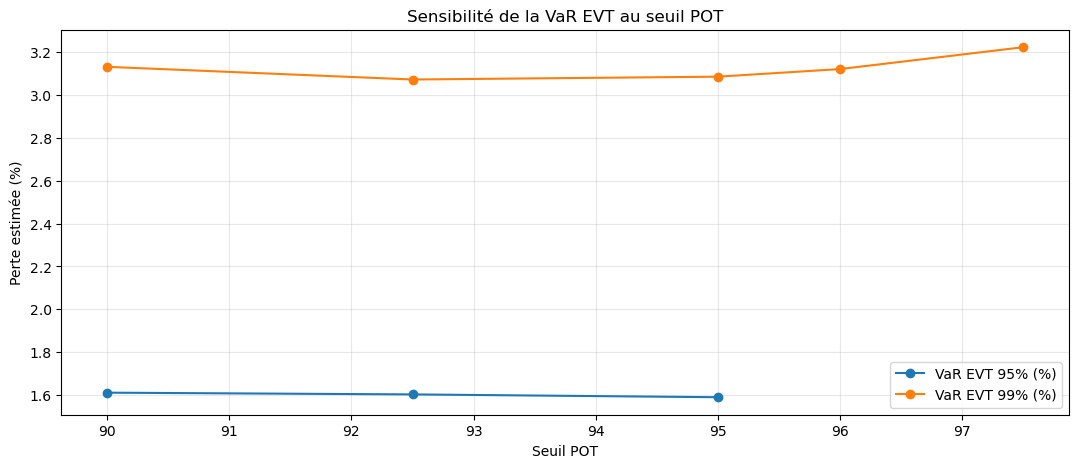

In [ ]:
threshold_quantiles = [0.9, 0.925, 0.95, 0.96, 0.975]

sensitivity_results = []

for q in threshold_quantiles:
    u = np.quantile(losses, q)
    exc = losses[losses > u] - u

    if len(exc) < 30:     # Skip si trop peu de points extrêmes
        continue

    xi, _, beta = genpareto.fit(exc, floc=0)
    p_u = len(exc) / len(losses)

    row = {
        "Seuil de quantile" : q,
        "Seuil" : u,
        "Nombre de dépassements" : len(exc),
        "Shape" : xi,
        "Scale" : beta
    }

    for confidence in CONFIDENCE_LEVELS:
        try:
            var_value = evt_var(losses, u, xi, beta, p_u, confidence)
        except ValueError:
            var_value = np.nan
        row[f"VaR EVT {confidence:.0%} (%)"] = var_value * 100

    sensitivity_results.append(row)

sensitivity_df = pd.DataFrame(sensitivity_results)
display(sensitivity_df)

plt.figure(figsize=(13, 5))
for col in ["VaR EVT 95% (%)", "VaR EVT 99% (%)"]:
    plt.plot(sensitivity_df["Seuil de quantile"] * 100, sensitivity_df[col], marker="o", label=col)
plt.title("Sensibilité de la VaR EVT au seuil POT")
plt.xlabel("Seuil POT")
plt.ylabel("Perte estimée (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Graphique de VaR EVT :**

- La VaR 99 % est stable. Elle reste entre 3,07 % et 3,22 % pour des seuils allant du 90e au 97,5e centile, soit un écart d'environ 0,15 point. Le résultat ne dépend donc pas fortement du choix du seuil.
- La VaR 95 % n'est pas testable partout. Pour les seuils à 96 % et 97,5 %, la fraction de dépassements (4 % et 2,5 %) est inférieure à 5 %, donc la formule ne s'applique pas (NaN). La VaR 95 % n'a de sens qu'avec un seuil plus bas que 95 %.
- La VaR 95 % est presque constante (1,59 % à 1,61 %), car elle se situe près du seuil lui-même.

**Paramètres de la GPD :**

- Forme $\xi$ : entre 0,24 et 0,34 pour les seuils de 90 % à 95 %. Cela confirme une queue lourde modérée, avec une variance finie ($\xi$ < 1/2).
- Forme $\xi$ à 97,5 % : 0,12, avec seulement 64 dépassements. L'estimation est peu fiable.
- Échelle $\sigma$ : elle augmente avec le seuil (0,66 % à 1,18 %). C'est normal, car $\sigma$ dépend du seuil choisi. Il ne faut donc pas la comparer telle quelle entre seuils.

$\Rightarrow$ **Le seuil à 90 % ou 95 % donne des résultats cohérents, avec environ 130 à 256 dépassements. Le seuil à 97,5 % est trop restrictif : seuls 64 dépassements alimentent l'ajustement, et la forme $\xi$ devient instable.**

## Conclusion

**Contexte :** les méthodes classiques de risque, comme la VaR gaussienne ou la volatilité historique, décrivent bien le quotidien des marchés mais sous-estiment les krachs. Le notebook s'intéresse donc à la queue de distribution des pertes du CAC 40, là où se trouvent les événements rares qui comptent le plus pour un investisseur.

**Méthodologie :** La méthode repose sur la théorie des valeurs extrêmes, dans son approche par dépassements de seuil. On fixe un seuil élevé, on ne garde que les pertes qui le dépassent, puis on ajuste une loi de Pareto généralisée sur ces excès. Cette loi permet ensuite d'estimer une VaR et une Expected Shortfall sans supposer une forme pour toute la distribution.

Ce travail permet surtout de tirer trois enseignements :

- Justifier l'abandon de l'hypothèse gaussienne pour le risque extrême. Les rendements du CAC 40 ont une queue plus épaisse que la loi normale, ce qui confirme que la modélisation de la queue doit être traitée séparément.
- Obtenir une mesure de risque extrême plus stable que l'historique seul. Au niveau de confiance de 99 %, l'historique repose sur très peu d'observations. Le modèle lisse cette information et produit une estimation plus robuste, avec une ES plus prudente.
- Vérifier que le résultat ne dépend pas trop d'un choix arbitraire. Le test de sensibilité au seuil montre que la VaR 99 % reste dans une fourchette étroite lorsque le seuil varie, ce qui rend la conclusion crédible.
  
**Ce que ce travail permet concrètement :** estimer, pour un portefeuille ou un indice, l'ordre de grandeur d'une perte journalière rare mais plausible, et comparer cette estimation à ce que donnerait un modèle gaussien. Il constitue une base solide pour un suivi du risque de queue, à condition de garder à l'esprit ses limites.

**Limites à garder en tête :** les excès ne sont pas indépendants, car les grosses pertes se regroupent dans le temps (2020 notamment). Le modèle est aussi statique, sans prise en compte de la volatilité variable, et il n'a pas été testé hors échantillon. Les conclusions sont donc à considérer comme une première approche exploratoire, non comme un outil de gestion de risque opérationnel.

**Suites possibles :** appliquer un declustering des dépassements, combiner GARCH et TVE, et faire un backtesting de la VaR sur une fenêtre glissante.